# Notebook 2: Creación del grafo y análisis

In [150]:
import pandas as pd
import networkx as nx
from community import community_louvain
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.cm import get_cmap

### **Obtención del archivo `user_interests.csv`**  

Para enriquecer nuestros datos, utilizamos un **modelo de lenguaje (LLM)**—en este caso, **DeepSeek**—para inferir los intereses y hobbies de cada usuario a partir del archivo `user_hashtags.csv`. Los resultados se almacenaron en `user_interests.csv`, lo que nos permitió avanzar en el análisis a pesar de las limitaciones de la plataforma.  

#### **Justificación del enfoque del grafo**  
Inicialmente, consideramos construir el grafo utilizando las conexiones directas (`.edges`). Sin embargo, debido al bajo número de usuarios seleccionados, obtuvimos **comunidades totalmente aisladas**, lo que hacía el grafo inútil para nuestro análisis.  

Para solucionar esto, optamos por una estructura alternativa:  
- **Nodos:** Usuarios.  
- **Aristas:** Conexiones basadas en **intereses compartidos** entre usuarios.  

Este enfoque permitió:  
- **Mayor conectividad** entre nodos, evitando comunidades aisladas.  
- **Un análisis más significativo** de las relaciones basadas en afinidades.  
- **Flexibilidad** para ajustar el peso de las aristas según la cantidad de intereses en común.  

En este *notebook*, nos centramos en la construcción y análisis de este grafo, detallando cómo la estrategia elegida superó las limitaciones iniciales.  
```

##### Cargamos el archivo data con todos los usuarios, y los intereses de cada uno.

In [54]:
# Cargar datos
data = pd.read_csv("user_interests.csv")

# Asegurarse de que la columna 'interests' sea de tipo string
data['interests'] = data['interests'].astype(str)
data['interests'] = data['interests'].fillna('')
data['interests'] = data['interests'].str.replace(r'\bnan\b|["\']', '', regex=True).str.lower().str.split(', ')

# Eliminar filas con 'NaN' en la columna 'interests'
data = data[data['interests'].str.len() > 1].reset_index(drop=True)

In [55]:
data

,user,interests
0,7846,"[gaming, technology, influencers]"
1,10350,"[gaming, books, sci-fi, fantasy, pop culture]"
2,15913,"[gaming, technology, entertainment, food]"
3,55113,"[poetry, literature, nature]"
4,681813,"[gaming, creativity]"
...,...,...
788,102765423,"[television shows, pop culture]"
789,102903198,"[gaming, mass effect, comics]"
790,103431502,"[gaming, call of duty, activism]"
791,103865085,"[space, astronomy, science]"


##### Generamos el grafo. Ponderamos las aristas según el número de intereses compartidos entre usuarios.

In [56]:
# Crear un grafo
G = nx.Graph()

# Añadir nodos (usuarios)
for user in data["user"]:
    G.add_node(user)

# Añadir aristas con pesos basados en intereses compartidos
for i in range(len(data)):
    for j in range(i + 1, len(data)):
        user1 = data.iloc[i]["user"]
        user2 = data.iloc[j]["user"]
        interests1 = set(data.iloc[i]["interests"])
        interests2 = set(data.iloc[j]["interests"])
        shared_interests = interests1.intersection(interests2)
        if shared_interests:
            G.add_edge(user1, user2, weight=len(shared_interests))  # Añadir pesos a las aristas

# Eliminar nodos aislados
G.remove_nodes_from(list(nx.isolates(G)))


In [57]:
num_nodos = G.number_of_nodes()
print("Número de nodos:", num_nodos)
num_aristas = G.number_of_edges()
print(f"Número de aristas: {num_aristas}")

Número de nodos: 789
Número de aristas: 86199


##### Detectamos las comunidades con el método de louvain, por su eficiencia computacional.

In [58]:
# Detectar comunidades (louvain)
comunidades_louvain = community_louvain.best_partition(G, weight='weight')
comunidades_louvain = pd.DataFrame(comunidades_louvain.items(), columns=['user', 'comunidad'])
comunidades_louvain = comunidades_louvain.groupby('comunidad')['user'].apply(list).reset_index(drop=True)
comunidades_louvain = comunidades_louvain.to_dict()

In [59]:
len(comunidades_louvain)

6

In [60]:
for i, comunidad in comunidades_louvain.items():
    for nodo in comunidad:
        G.nodes[nodo]['community'] = i

In [61]:
for i, community in comunidades_louvain.items():
    print(f"Comunidad {i}: {community}")

Comunidad 0: [7846, 10350, 15913, 681813, 756379, 769584, 794186, 1065921, 1183041, 2260771, 2811851, 3359851, 3462421, 4219131, 4893411, 5980142, 6068612, 6572452, 7079062, 7081402, 7098022, 7377812, 7384432, 7860742, 7861312, 8207762, 8715652, 9199472, 9955652, 10671602, 11487372, 14050306, 14110133, 14111650, 14144060, 14165096, 14192988, 14239780, 14303746, 14311802, 14326533, 14412605, 14424667, 14456842, 14464369, 14589257, 14683518, 14743923, 14876672, 14888584, 15271920, 15575251, 15665127, 15758036, 15775181, 15999863, 16038438, 16079941, 16098603, 16150457, 16218063, 16264063, 16265412, 16507381, 16583999, 16799897, 16908436, 16909832, 17037417, 17047105, 17064514, 17092862, 17105214, 17158189, 17176990, 17738564, 17759701, 17983020, 18069427, 18125335, 18130749, 18444530, 18445879, 18488495, 18501326, 18602163, 18666844, 18709570, 18742444, 18781900, 18819743, 18849313, 18927441, 18959811, 19049747, 19136295, 19311729, 19415126, 19490867, 19507713, 19663597, 20106337, 201068

##### Creamos un dataframe con los intereses más comunes en cada comunidad.

In [62]:
# Crear un dataframe con los intereses más comunes en cada comunidad.
community_interests = {}
for index, community in comunidades_louvain.items():
    interests = []
    for user in community:
        user_interests = data[data["user"] == user]["interests"].values[0]
        interests.extend(user_interests)
    community_interests[index] = list(set(interests))

In [132]:
interests_per_comunity = pd.DataFrame(list(community_interests.values())).fillna('').apply(lambda x: [interest for interest in x if interest], axis=1)
interests_per_comunity = interests_per_comunity.apply(sorted)

In [133]:
interests = pd.read_csv('interests_per_comunity.csv', header=None)[0]
interests = interests.str.replace(r'["\'\[\]]', '', regex=True).str.split(', ')
interests = interests.apply(sorted)

In [135]:
interests_per_comunity

0    [activism, avengers, awards, battlefield, book...
1    [activism, art, avengers, books, censorship, f...
2    [activism, art, avril lavigne, bands, books, c...
3                         [mma, nfl, olympics, sports]
4    [activism, astrobiology, astronomy, climate, e...
5           [advertising, branding, coffee, marketing]
dtype: object

In [134]:
interests

0    [activism, avengers, awards, battlefield, book...
1    [activism, art, avengers, books, censorship, f...
2    [activism, art, avril lavigne, bands, books, c...
3                         [mma, nfl, olympics, sports]
4    [activism, astrobiology, astronomy, climate, e...
5           [advertising, branding, coffee, marketing]
Name: 0, dtype: object

##### Pasando las listas anteriores a un LLM para filtrar categorías, obtenemos los siguientes intereses compartidos en cada comunidad.

In [ ]:
{0:5, 1:3, 2:4, 3:3, 4:, 5:}

In [ ]:
interests_per_comunity = [['gaming', 'science', 'comics', 'streaming', 'technology', 'humor'],
                          ['activism', 'books', 'technology', 'politics', 'journalism', 'movies'],
                          ['tv shows', 'celebrities', 'music', 'activism', 'comedy', 'pop culture'],
                          ['sports', 'nfl', 'olympics', 'mma'], 
                          ['space', 'nasa', 'science', 'astronomy', 'climate', 'geek culture'],
                          ['marketing', 'advertising', 'branding', 'coffee']]

##### A continuación calculamos una serie de medidas del grafo.

In [14]:
# Centralidad de grado ponderada
degree_centrality = nx.degree_centrality(G)
nx.set_node_attributes(G, degree_centrality, "betweenness_centrality")

In [15]:
# Métricas globales
density = nx.density(G)
print("Densidad de la red:", density)
clustering_coefficient = nx.average_clustering(G, weight="weight")
print("Coeficiente de agrupamiento promedio:", clustering_coefficient)

Densidad de la red: 0.2772866765744726
Coeficiente de agrupamiento promedio: 0.28773082241470077


In [16]:
connected_components = list(nx.connected_components(G))
num_componentes_conex = len(connected_components)
print(f"Número de componentes conexas: {num_componentes_conex}")

Número de componentes conexas: 1


In [17]:
largest_component = max(connected_components, key=len)
G_largest = G.subgraph(largest_component).copy()
print(f"Número de nodos en el componente más grande: {G_largest.number_of_nodes()}")
print(f"Número de aristas en el componente más grande: {G_largest.number_of_edges()}")

Número de nodos en el componente más grande: 789
Número de aristas en el componente más grande: 86199


In [18]:
# Calcular diámetro y radio en el componente más grande
diameter = nx.diameter(G_largest)
radius = nx.radius(G_largest)
print("Diámetro de la red (componente más grande):", diameter)
print("Radio de la red (componente más grande):", radius)

Diámetro de la red (componente más grande): 5
Radio de la red (componente más grande): 3


In [19]:
# --- Exportar el grafo para Gephi ---
nx.write_gexf(G, "red_social.gexf")

#### Generamos los un gráfico de barras con los los 3 pares de comunidades más conectadas entre sí, y el número de aristas que atraviesan de una comunidad a la otra.

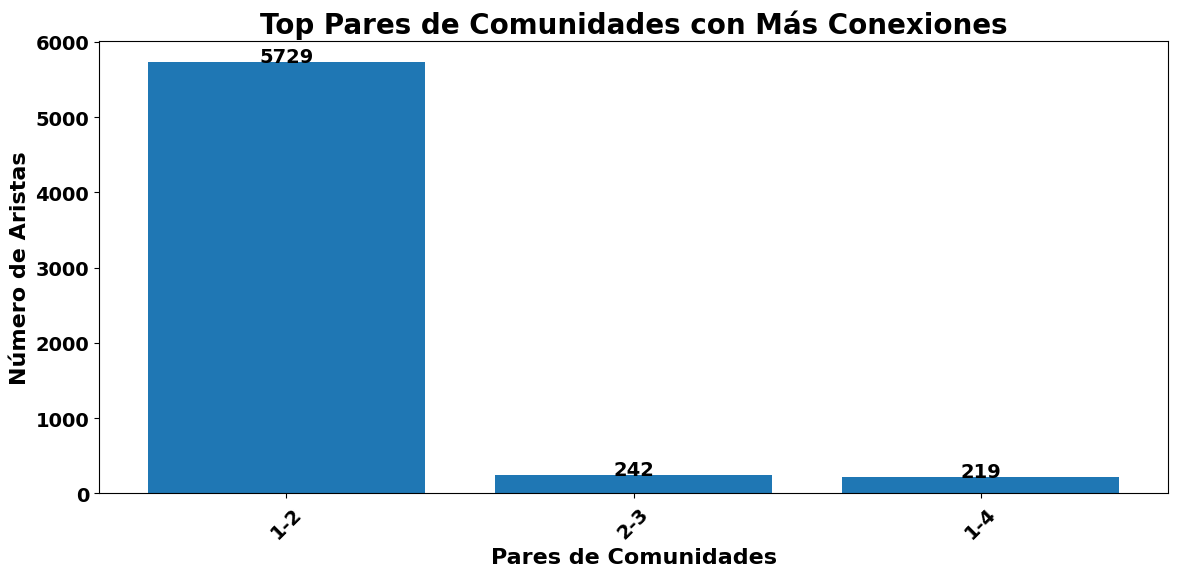

Top pares de comunidades con más conexiones:
Comunidades 1-2: 5729 aristas
Comunidades 2-3: 242 aristas
Comunidades 1-4: 219 aristas


In [158]:
from collections import defaultdict

# Suponiendo que ya tienes:
# - G: tu grafo de NetworkX
# - interests_per_comunity: pandas Series con índices como IDs de comunidad y valores como listas de IDs de vértices

def contar_aristas_entre_comunidades(G, comunidades):
    # Diccionario para almacenar el conteo de aristas entre cada par de comunidades
    conteo_aristas = defaultdict(int)
    corrector_comunidades = {0:1, 1:4, 2:2, 3:6, 4:3, 5:5}
    # Crear un mapeo de nodo a comunidad para acceso rápido
    nodo_a_comunidad = {}
    for comunidad, nodos in comunidades.items():
        for nodo in nodos:
            nodo_a_comunidad[nodo] = corrector_comunidades[comunidad]
    # Contar aristas entre comunidades diferentes
    for u, v in G.edges():
        # Verificar que ambos nodos estén en el mapeo
        if u in nodo_a_comunidad and v in nodo_a_comunidad:
            comunidad_u = nodo_a_comunidad[u]
            comunidad_v = nodo_a_comunidad[v]
            # Solo contar si las comunidades son diferentes
            if comunidad_u != comunidad_v:
                # Ordenar las comunidades para evitar duplicados (A-B y B-A)
                par_comunidades = tuple(sorted([comunidad_u, comunidad_v]))
                conteo_aristas[par_comunidades] += 1
    
    return conteo_aristas

def visualizar_top_conexiones(conteo_aristas, top_n=10, guardar_archivo=None):
    # Configurar el estilo general para mejor legibilidad
    plt.rcParams['font.size'] = 14
    plt.rcParams['font.weight'] = 'bold'
    plt.rcParams['axes.labelweight'] = 'bold'
    plt.rcParams['axes.titleweight'] = 'bold'
    plt.rcParams['axes.labelsize'] = 16
    plt.rcParams['axes.titlesize'] = 20
    plt.rcParams['xtick.labelsize'] = 14
    plt.rcParams['ytick.labelsize'] = 14
    # Convertir a lista de tuplas (par_comunidades, conteo)
    pares_ordenados = sorted(conteo_aristas.items(), key=lambda x: x[1], reverse=True)
    
    # Tomar los top_n pares
    top_pares = pares_ordenados[:top_n]
    
    # Preparar datos para visualización
    pares = [f"{c1}-{c2}" for (c1, c2), _ in top_pares]
    conteos = [conteo for _, conteo in top_pares]
    
    # Crear figura con fondo transparente
    fig = plt.figure(figsize=(12, 6))
    # Hacer que el fondo de la figura sea transparente
    fig.patch.set_alpha(0.0)
    
    # Crear gráfico de barras con fondo transparente
    ax = plt.subplot(111)
    ax.patch.set_alpha(0.0)  # Hacer que el fondo del subplot sea transparente
    
    bars = ax.bar(pares, conteos)
    ax.set_xlabel('Pares de Comunidades')
    ax.set_ylabel('Número de Aristas')
    ax.set_title('Top Pares de Comunidades con Más Conexiones')
    plt.xticks(rotation=45)
    plt.tight_layout()
    
    # Mostrar valores en las barras
    for i, v in enumerate(conteos):
        ax.text(i, v + 0.5, str(v), ha='center')
    
    # Guardar la figura con fondo transparente si se especifica un nombre de archivo
    if guardar_archivo:
        plt.savefig(guardar_archivo, transparent=True, bbox_inches='tight', dpi=300)
    
    plt.show()
    
    return top_pares

# Ejemplo de uso (descomenta y ajusta según tus datos)

# Suponiendo que G es tu grafo y interests_per_comunity es tu Series de pandas
conteo = contar_aristas_entre_comunidades(G, comunidades_louvain)
top_pares = visualizar_top_conexiones(conteo, top_n=3, guardar_archivo="top_conexiones.png")
print("Top pares de comunidades con más conexiones:")
for (c1, c2), conteo in top_pares:
    print(f"Comunidades {c1}-{c2}: {conteo} aristas")

#### Creamos un grafo de comunidades.

In [188]:
# Aplicar algoritmo de separación de nodos para evitar solapamiento
def separar_nodos(pos, node_sizes, iterations=50):
    """Ajusta las posiciones para evitar solapamiento de nodos."""
    for _ in range(iterations):
        displacement = {node: np.array([0.0, 0.0]) for node in pos}
        # Calcular fuerzas de repulsión
        for i, node1 in enumerate(pos):
            for node2 in pos:
                if node1 != node2:
                    # Calcular distancia entre nodos
                    delta = np.array(pos[node1]) - np.array(pos[node2])
                    distance = max(0.01, np.linalg.norm(delta))
                    
                    # Calcular radio combinado (basado en tamaño de nodos)
                    combined_radius = (np.sqrt(node_sizes[i]) + 
                                      np.sqrt(node_sizes[list(pos.keys()).index(node2)])) / 200
                    
                    # Si están demasiado cerca, aplicar fuerza de repulsión
                    if distance < combined_radius:
                        # Normalizar vector de dirección
                        direction = delta / distance
                        # Fuerza proporcional a la superposición
                        force = direction * (combined_radius - distance) * 0.1
                        displacement[node1] += force
                        displacement[node2] -= force
        
        # Aplicar desplazamientos, pero mantener dentro de los límites
        for node in pos:
            pos[node] = np.array(pos[node]) + displacement[node]
            # Limitar a los bordes
            x, y = pos[node]
            pos[node] = (max(0.05, min(0.95, x)), max(0.05, min(0.95, y)))
    
    return pos

In [246]:
# Función corregida para ajustar posición de etiquetas de aristas
def ajustar_posicion_etiquetas(pos, edge_labels, G):
    """
    Ajusta la posición de las etiquetas de las aristas para evitar solapamiento.
    """
    # Crear un diccionario para almacenar las posiciones de las etiquetas
    label_pos = {}
    
    # Verificar que solo trabajamos con aristas válidas (cuyos nodos existen en pos)
    valid_edges = {}
    for (u, v), label in edge_labels.items():
        if u in pos and v in pos:  # Verificar que ambos nodos existen en pos
            valid_edges[(u, v)] = label
        else:
            print(f"Advertencia: La arista ({u}, {v}) contiene nodos que no están en el diccionario de posiciones")
    
    # Para cada arista válida, calcular una posición inicial para su etiqueta
    for (u, v), label in valid_edges.items():
        # Posición media entre los nodos
        x = (pos[u][0] + pos[v][0]) / 2.0
        y = (pos[u][1] + pos[v][1]) / 2.0
        
        # Añadir un pequeño desplazamiento aleatorio para evitar solapamientos iniciales
        offset = 0.03 * np.random.rand()
        angle = 2 * np.pi * np.random.rand()
        x += offset * np.cos(angle)
        y += offset * np.sin(angle)
        
        label_pos[(u, v)] = (x, y)
    
    # Iterar para ajustar posiciones y evitar solapamientos
    for _ in range(30):  # 30 iteraciones para ajustar
        edges_list = list(valid_edges.keys())
        for i in range(len(edges_list)):
            for j in range(i+1, len(edges_list)):
                u1, v1 = edges_list[i]
                u2, v2 = edges_list[j]
                
                # Calcular distancia entre etiquetas
                x1, y1 = label_pos[(u1, v1)]
                x2, y2 = label_pos[(u2, v2)]
                dx = x2 - x1
                dy = y2 - y1
                dist = np.sqrt(dx*dx + dy*dy)
                
                # Si están demasiado cerca, separarlas
                min_dist = 0.07  # Distancia mínima entre etiquetas
                if dist < min_dist:
                    # Vector de dirección normalizado
                    if dist > 0:
                        dx /= dist
                        dy /= dist
                    else:
                        dx = 0.01 * (np.random.rand() - 0.5)
                        dy = 0.01 * (np.random.rand() - 0.5)
                    
                    # Aplicar fuerza de repulsión
                    force = 0.01 * (min_dist - dist) / min_dist
                    label_pos[(u1, v1)] = (x1 - dx * force, y1 - dy * force)
                    label_pos[(u2, v2)] = (x2 + dx * force, y2 + dy * force)
    
    return label_pos

In [273]:
def visualizar_grafo_comunidades(conteo_aristas, comunidades, min_conexiones=1, guardar_archivo=None, 
                                 colores_comunidades=None, color_por_defecto='#1f77b4'):
    """
    Visualiza un grafo simplificado donde los nodos son comunidades y las aristas
    representan conexiones entre comunidades con pesos.
    
    Args:
        conteo_aristas: Diccionario con pares de comunidades como claves y número de conexiones como valores
        comunidades: Series de pandas con comunidades como índices y listas de nodos como valores
        min_conexiones: Número mínimo de conexiones para mostrar una arista
        guardar_archivo: Nombre del archivo para guardar la imagen (opcional)
    """
    # Configurar el estilo general para mejor legibilidad
    plt.rcParams['font.size'] = 14
    plt.rcParams['font.weight'] = 'bold'
    plt.rcParams['axes.labelweight'] = 'bold'
    plt.rcParams['axes.titleweight'] = 'bold'
    
    # Crear un nuevo grafo para las comunidades
    G_comunidades = nx.Graph()
    
    # Obtener todas las comunidades únicas
    todas_comunidades = set()
    for (com1, com2) in conteo_aristas.keys():
        todas_comunidades.add(com1)
        todas_comunidades.add(com2)
    
    corrector_comunidades = {0:1, 1:4, 2:2, 3:6, 4:3, 5:5}
    # Añadir nodos (comunidades)
    for comunidad in comunidades:
        # Calcular el tamaño del nodo basado en el número de miembros en la comunidad
        if comunidad in comunidades:
            tamano = len(comunidades[comunidad])
        else:
            tamano = 10  # Tamaño por defecto si no hay información

        G_comunidades.add_node(corrector_comunidades[comunidad], size=tamano)
    
    # Añadir aristas con pesos
    for (com1, com2), peso in conteo_aristas.items():
        if peso >= min_conexiones:  # Solo añadir aristas con peso mínimo
            G_comunidades.add_edge(com1, com2, weight=peso)

    # Obtener tamaños de nodos con escala raíz cuadrada
    node_sizes = []
    if len(G_comunidades.nodes()) > 0:
        sizes = [G_comunidades.nodes[node]['size'] for node in G_comunidades.nodes()]
        min_size = min(sizes)
        max_size = max(sizes)
        
        # Normalizar a un rango más compacto (300-1500)
        if max(sizes) > min(sizes):
            normalized_sizes = [1500 + (size - min(sizes)) * 3000 / (max(sizes) - min(sizes)) 
                            for size in sizes]
        else:
            normalized_sizes = [500] * len(sizes)
        
        # Asignar tamaños a nodos
        for i, node in enumerate(G_comunidades.nodes()):
            node_sizes.append(normalized_sizes[i])
    else:
        node_sizes = [500]  # Tamaño por defecto si no hay nodos
    
    # Dibujar aristas con grosor proporcional al peso
    edge_weights = [G_comunidades[u][v]['weight'] for u, v in G_comunidades.edges()]
    max_weight = max(edge_weights) if edge_weights else 1
    min_weight = min(edge_weights) if edge_weights else 1

    # Aplicar escala logarítmica a los grosores de aristas para mejor visualización
    log_weights = [np.log1p(w - min_weight + 1) for w in edge_weights]
    max_log_weight = max(log_weights) if log_weights else 1
    normalized_weights = [5 + (w / max_log_weight) * 15 for w in log_weights]
    
    # Asignar colores a los nodos
    node_colors = []
    for node in G_comunidades.nodes():
        if colores_comunidades and node in colores_comunidades:
            node_colors.append(colores_comunidades[node])
        else:
            node_colors.append(color_por_defecto)
    
    # Crear figura con fondo transparente
    fig = plt.figure(figsize=(16, 12))
    fig.patch.set_alpha(0.0)
    
    ax = plt.subplot(111)
    ax.patch.set_alpha(0.0)
    
    # Obtener posiciones de los nodos usando un layout que separa bien los nodos
    # Usar un valor de k más pequeño para acercar los nodos y center=True para centrarlos
    pos = nx.spring_layout(G_comunidades, k=0.1, iterations=1000, seed=42, center=(0.5, 0.5), scale=0.9)
    pos = separar_nodos(pos, node_sizes)
    
    # Asegurarse de que todos los nodos estén dentro del área visible
    for node in pos:
        x, y = pos[node]
        # Limitar las coordenadas al rango [0.05, 0.95] para mantener margen
        pos[node] = (max(0.05, min(0.95, x)), max(0.05, min(0.95, y)))
    
    # Mejorar la apariencia de los nodos
    nodes = nx.draw_networkx_nodes(
        G_comunidades, 
        pos, 
        node_size=node_sizes,
        node_color=node_colors,
        alpha=0.9,
        edgecolors='black',
        linewidths=2
    )

    # Dibujar aristas con colores basados en peso
    edges = nx.draw_networkx_edges(
        G_comunidades, 
        pos, 
        width=normalized_weights,
        alpha=0.8,  # Curvar más las aristas para mejor visualización
    )
    
    # Eliminar ejes
    plt.axis('off')
    
    # Ajustar los márgenes
    plt.tight_layout()
    
    # Guardar la figura con fondo transparente si se especifica un nombre de archivo
    if guardar_archivo:
        plt.savefig(guardar_archivo, transparent=True, bbox_inches='tight', dpi=300)
    
    plt.show()
    
    return G_comunidades

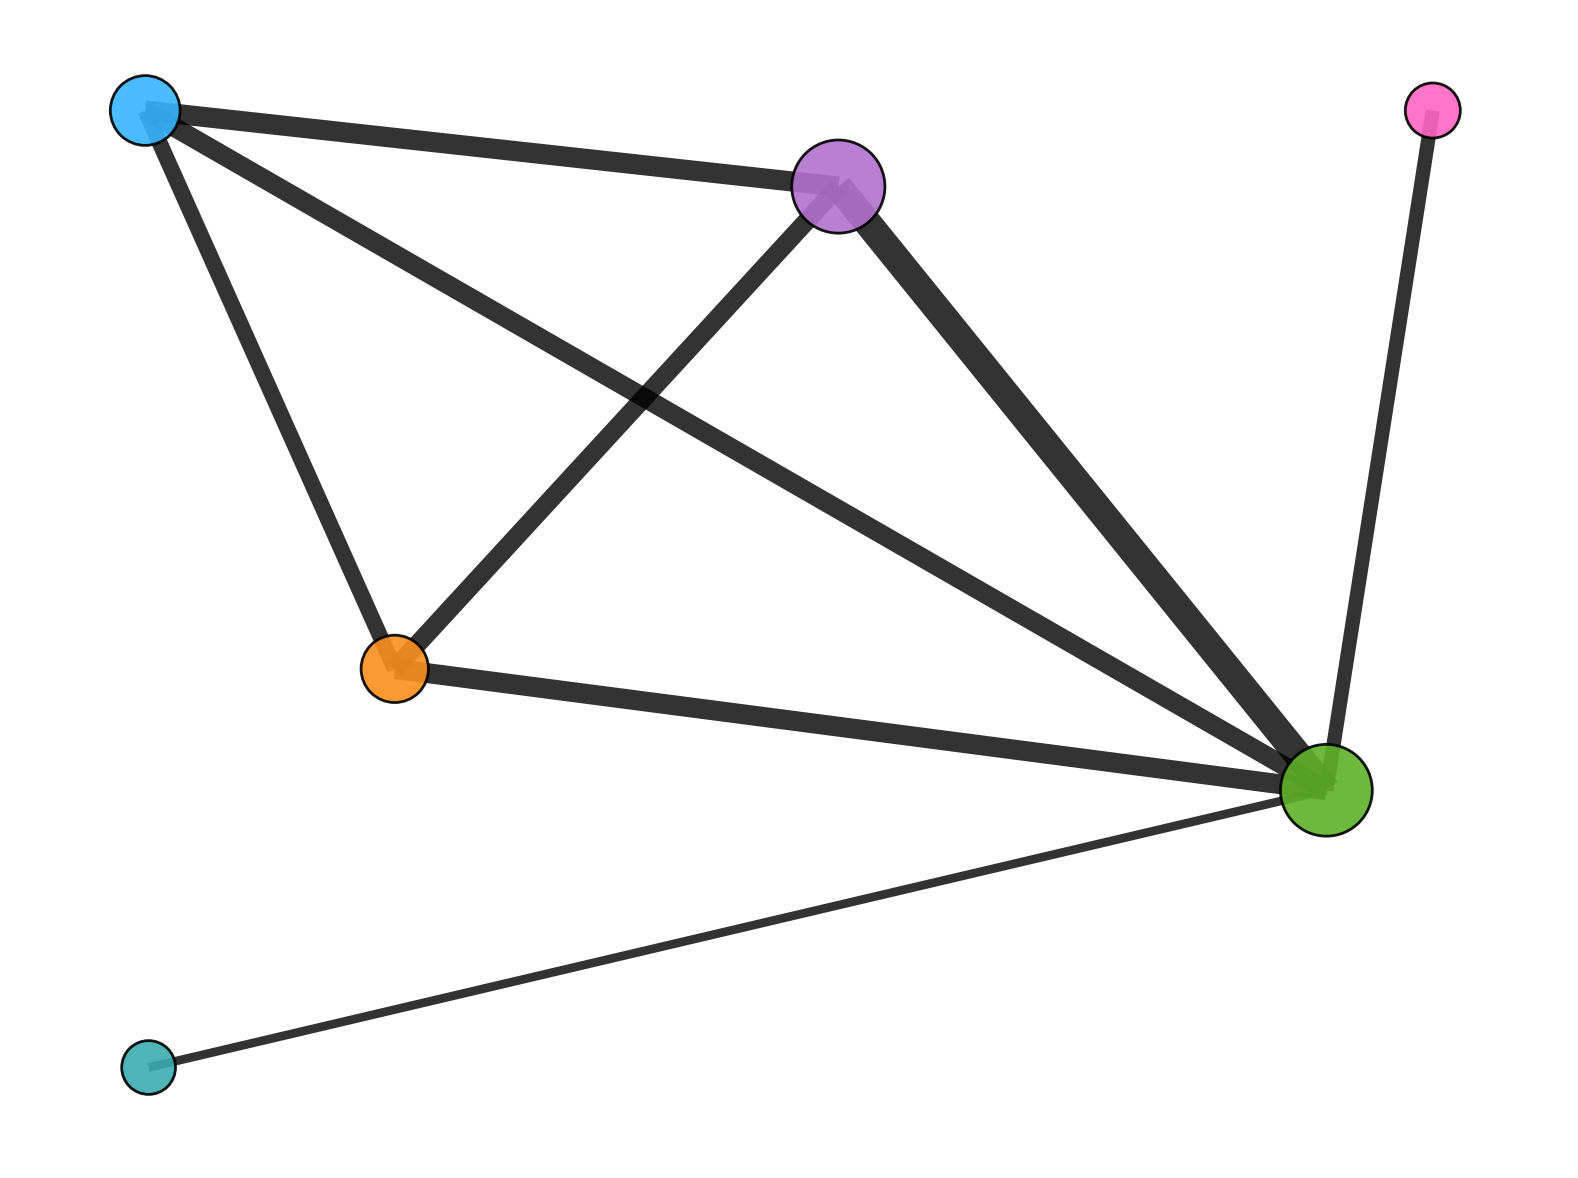

In [275]:
# Visualizar el grafo de comunidades
colores_comunidades = {
    1: '#5EB229',  # Verde
    2: '#B272CE',  # Morado
    3: '#38B6FF',  # Azul
    4: '#FB901D',  # Naranja
    5: '#3CACAE',  # Cian
    6: '#FF66C4',  # Rosa
}

conteo = contar_aristas_entre_comunidades(G, comunidades_louvain)
# Visualizar el grafo de comunidades con colores personalizados
G_comunidades = visualizar_grafo_comunidades(
    conteo, 
    comunidades_louvain, 
    min_conexiones=1,
    colores_comunidades=colores_comunidades,
)

#### Creamos un diagrama de sectores que representa el porcentaje del total de aristas que contiene cada comunidad.

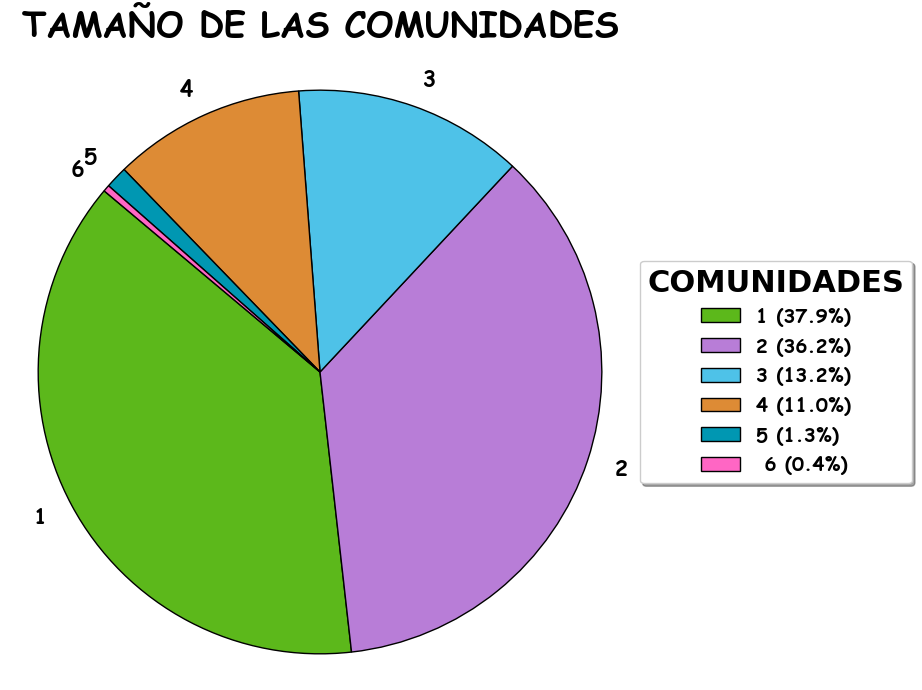

In [272]:
# Datos de ejemplo
categorias = ['1', '2', '3', '4', '5', ' 6']
valores = [37.9, 36.25, 13.18, 11.03, 1.27, 0.38]

# Colores específicos
colores = ['#5CB81B', '#B87DD7', '#4EC2E8', '#DD8B35', '#0097B2', '#FF66C4']

# Crear el gráfico de sectores
plt.figure(figsize=(8, 8))  # Tamaño del gráfico
wedges, texts, autotexts = plt.pie(valores, labels=categorias, colors=colores, autopct='', startangle=140, wedgeprops={'edgecolor': 'black'})

# Personalizar las etiquetas de cada sector
for text in texts:
    text.set_fontsize(15.5)  # Tamaño de la fuente
    text.set_fontweight('bold')  # Negrita
    text.set_fontfamily('Comic Sans MS')  # Fuente más visual

# Personalizar el gráfico
plt.title('TAMAÑO DE LAS COMUNIDADES', fontsize=25, fontweight='bold', fontfamily='Comic Sans MS', pad=20)  # Título en mayúsculas y más espacio
plt.axis('equal')  # Asegura que el gráfico sea un círculo

porcentajes = [f'{categorias[i]} ({valores[i]/sum(valores)*100:.1f}%)' for i in range(len(categorias))]
# Personalizar la leyenda
plt.legend(title='COMUNIDADES', loc='center left', bbox_to_anchor=(1, 0.5), fontsize=18, title_fontsize=22,labels=porcentajes, prop={'family': 'Comic Sans MS'}, frameon=True, fancybox=True, shadow=True)  # Leyenda más grande y estilizada

plt.show()

### Análisis de resultados
##### Comunidad 1 (Gaming/Tecnología):
Tiene fuertes conexiones con la Comunidad 2 (Activismo/Cultura), especialmente en temas como política, periodismo y cine, lo que se refleja en una arista muy gruesa en el grafo de comunidades. Estos usuarios tecnológicos interactúan frecuentemente con perfiles activistas, formando un núcleo central de discusión social y digital. Sin embargo, sus vínculos con la Comunidad 3 (Entretenimiento) son más débiles y se limitan principalmente al streaming y al cine, evidenciado por aristas delgadas y escasas en la visualización.
##### Comunidad 2 (Activismo/Cultura):
Destaca por su solapamiento significativo con la Comunidad 1, compartiendo intereses en política y medios, lo que crea una subred densa y altamente conectada. Estos usuarios colaboran en debates sociales y proyectos mediáticos, actuando como puentes naturales entre mundos digitales y activistas. Por el contrario, su interacción con la Comunidad 3 es mínima, reducida a temas puntuales como adaptaciones de libros a películas, visible en el grafo por conexiones dispersas y de bajo peso.
##### Comunidad 3 (Entretenimiento/Celebridades):
Es la más aislada del grafo, con la mayoría de sus conexiones concentradas internamente en temas como TV shows, música pop y celebridades. Las pocas aristas que la unen a otras comunidades son menos numerosas y corresponden a intereses marginales compartidos (ej: cine). Esta desconexión sugiere patrones de consumo cultural distintos y menor engagement con debates sociales o tecnológicos, reflejando una posición periférica en la red.
#### Comunidad 4 (Deportes/Fitness):
Esta comunidad más pequeña se centra en intereses como deportes, fitness y vida saludable. En el grafo, aparece conectada débilmente con la Comunidad 1 (Gaming/Tecnología) a través de plataformas de streaming deportivo, y con la Comunidad 3 (Entretenimiento) mediante programas de televisión deportivos. Sin embargo, sus conexiones son limitadas, mostrando aristas delgadas y pocos nodos compartidos, lo que refleja un nicho más especializado dentro de la red..
##### Comunidad 5 (Arte/Diseño):
Con un tamaño aún menor, esta agrupación se destaca por intereses como arte visual, diseño gráfico y fotografía. En el grafo, se observan conexiones puntuales con la Comunidad 2 (Activismo/Cultura) a través de proyectos artísticos con mensajes sociales, y con la Comunidad 1 (Gaming/Tecnología) por el diseño de videojuegos. Aunque las aristas son escasas, tienen un peso moderado, indicando colaboraciones específicas pero significativas entre estos grupos.
##### Comunidad 6 (Educación/Ciencia):
La más pequeña de todas, esta comunidad se enfoca en educación, ciencia avanzada e investigación. En el grafo, se conecta principalmente con la Comunidad 1 (Gaming/Tecnología) mediante debates sobre innovación científica, y con la Comunidad 2 (Activismo/Cultura) a través de campañas educativas. Las aristas son pocas pero bien definidas, sugiriendo interacciones de alto valor aunque poco frecuentes. Su posición periférica en la red resalta su carácter especializado y su rol como fuente de conocimiento para otras comunidades.